# Model 4 — Ridge regression, Cases 1–3

**Idea:** the same linear equation as MLR, ŷ = β₀ + β₁x₁ + … + βₚxₚ, but β is chosen to minimise

  Σ(y − ŷ)² + α · Σβᵢ²

The extra term (L2 penalty) shrinks the coefficients towards 0. When inputs are strongly correlated
(yesterday's power and GHI, module and ambient temperature), plain MLR can give them large or wrong-signed
coefficients; Ridge keeps them stable. With α = 0, Ridge is exactly MLR.

- **Scaling:** the penalty treats all coefficients equally, so inputs are standardised first (mean 0, std 1).
  The scaler is fitted on training data only.
- **Tuning:** α is chosen per case by the lowest validation RMSE. The test set is not used for the choice.

Same data, inputs, split, scoring window and metrics as the MLR notebook.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

## 1. Settings

In [2]:
# Works whether the notebook is opened from src/ or from the project folder.
ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
CLEAN_CSV = ROOT / "Data" / "Clean" / "Winter_Clean.csv"
RESULTS = ROOT / "results"

CAPACITY_MW = 21.5
BAND_MW = 0.07 * CAPACITY_MW  # ±7% of capacity (GERC 2019 tolerance) = 1.505 MW

# Scoring window 07:00-18:15 (blocks 29-74): the plant never generates outside it.
DAY_FIRST_BLOCK, DAY_LAST_BLOCK = 29, 74

# Chronological split by target day (dates inclusive).
SPLITS = {
    "train": ("2025-10-15", "2026-01-14"),
    "val": ("2026-01-15", "2026-02-07"),
    "test": ("2026-02-08", "2026-02-14"),
}

# Short names for the CSV columns.
RENAME = {
    "Act. Power (MW)": "power",
    "W-GHI (W/m2)": "ghi",
    "W-MODT- (°C)": "modt",
    "W-AMBT (°C)": "ambt",
    "W-WSPD (m/s)": "wspd",
    "W-WDIR- (Degree)": "wdir",
}
WEATHER = ["ghi", "modt", "ambt", "wspd", "wdir"]

CASES = {
    "Case 1": ["power_D"],
    "Case 2": ["power_D"] + [f"{w}_D" for w in WEATHER],
    "Case 3": ["power_D"] + [f"{w}_D" for w in WEATHER] + [f"{w}_D+1" for w in WEATHER],
}

# Candidate penalty strengths: 0.01 to 100,000, four per factor of 10.
ALPHAS = np.logspace(-2, 5, 29)

## 2. Load the clean data and label each day with its split

In [3]:
df = pd.read_csv(CLEAN_CSV, parse_dates=["TimeStamp", "Date"]).rename(columns=RENAME)

df["split"] = None
for name, (start, end) in SPLITS.items():
    df.loc[df["Date"].between(start, end), "split"] = name
assert df["split"].notna().all(), "some dates fall outside every split"

df.groupby("split")["Date"].agg(["min", "max", "nunique"]).loc[["train", "val", "test"]]

,min,max,nunique
split,,,
train,2025-10-15,2026-01-14,92
val,2026-01-15,2026-02-07,24
test,2026-02-08,2026-02-14,7


## 3. Build the inputs (identical to MLR)

`_D` = value at the same block on the previous day, `_D+1` = value on the target day (Case 3 only).

In [4]:
by_block = df.groupby("Block")
for col in ["power"] + WEATHER:
    df[f"{col}_D"] = by_block[col].shift(1)
for w in WEATHER:
    df[f"{w}_D+1"] = df[w]

# 15 Oct has no previous day, so it has no inputs.
df = df.dropna(subset=["power_D"]).reset_index(drop=True)

daytime = df[df["Block"].between(DAY_FIRST_BLOCK, DAY_LAST_BLOCK)].copy()
train = daytime[daytime["split"] == "train"]
val = daytime[daytime["split"] == "val"]

print("daytime rows per split:", daytime["split"].value_counts()[["train", "val", "test"]].to_dict())

daytime rows per split: {'train': 4186, 'val': 1104, 'test': 322}


## 4. Metrics

In [5]:
def evaluate(actual, forecast):
    err = forecast - actual
    mae = err.abs().mean()
    rmse = np.sqrt((err**2).mean())
    # R² = 1 - SS_res / SS_tot: share of variation explained vs always predicting the mean.
    r2 = 1 - (err**2).sum() / ((actual - actual.mean()) ** 2).sum()
    return {
        "MAE (MW)": mae,
        "RMSE (MW)": rmse,
        "nMAE (%)": 100 * mae / CAPACITY_MW,
        "nRMSE (%)": 100 * rmse / CAPACITY_MW,
        "Within ±7% (%)": 100 * (err.abs() <= BAND_MW).mean(),
        "R² (%)": 100 * r2,
        "Blocks": len(err),
    }


def skill_score(rmse, rmse_persistence):
    # 0 = no better than persistence, positive = better, negative = worse.
    return 100 * (1 - rmse / rmse_persistence)


def ridge_model(alpha):
    # Scaler + Ridge in one object: fit() learns the scaling from the data it is given (training only).
    return make_pipeline(StandardScaler(), Ridge(alpha=alpha))

## 5. Tune α on validation

For each case and each candidate α: fit on training, record training and validation RMSE and the coefficients.
The α with the lowest validation RMSE is kept (training RMSE always prefers the smallest α, so it can't choose α).

In [6]:
search = []
for case, features in CASES.items():
    for alpha in ALPHAS:
        model = ridge_model(alpha).fit(train[features], train["power"])
        train_pred = np.clip(model.predict(train[features]), 0, CAPACITY_MW)
        val_pred = np.clip(model.predict(val[features]), 0, CAPACITY_MW)
        search.append({
            "case": case,
            "alpha": alpha,
            "train RMSE (MW)": evaluate(train["power"], train_pred)["RMSE (MW)"],
            "val RMSE (MW)": evaluate(val["power"], val_pred)["RMSE (MW)"],
            # standardised coefficients at this α (for the website's slider)
            **{f"coef {f}": c for f, c in zip(features, model[-1].coef_)},
        })
search = pd.DataFrame(search)

best_alpha = search.loc[search.groupby("case")["val RMSE (MW)"].idxmin()].set_index("case")
best_alpha[["alpha", "train RMSE (MW)", "val RMSE (MW)"]]

,alpha,train RMSE (MW),val RMSE (MW)
case,,,
Case 1,100.000000,1.835424,2.092180
Case 2,177.827941,1.817256,2.019018
Case 3,0.010000,1.141665,1.522139


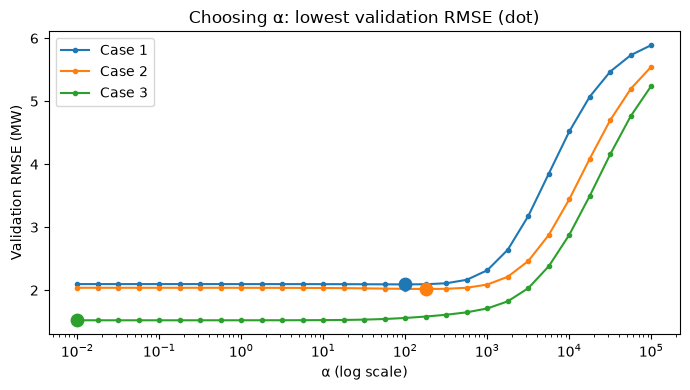

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for case, part in search.groupby("case"):
    ax.plot(part["alpha"], part["val RMSE (MW)"], marker=".", label=case)
    ax.scatter(best_alpha.loc[case, "alpha"], best_alpha.loc[case, "val RMSE (MW)"], s=80, zorder=3)
ax.set_xscale("log")
ax.set_xlabel("α (log scale)")
ax.set_ylabel("Validation RMSE (MW)")
ax.set_title("Choosing α: lowest validation RMSE (dot)")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Fit the final model per case with its chosen α

In [8]:
models = {}
for case, features in CASES.items():
    model = ridge_model(best_alpha.loc[case, "alpha"]).fit(train[features], train["power"])
    daytime[case] = np.clip(model.predict(daytime[features]), 0, CAPACITY_MW)
    models[case] = model

## 7. Scores: every case on every split

In [9]:
rows = []
for case in CASES:
    for split in ["train", "val", "test"]:
        part = daytime[daytime["split"] == split]
        scores = evaluate(part["power"], part[case])
        rmse_persistence = evaluate(part["power"], part["power_D"])["RMSE (MW)"]
        rows.append({
            "case": case,
            "alpha": best_alpha.loc[case, "alpha"],
            "split": split,
            **scores,
            "Skill vs persistence (%)": skill_score(scores["RMSE (MW)"], rmse_persistence),
        })

metrics = pd.DataFrame(rows).round(3)
metrics

,case,alpha,split,MAE (MW),RMSE (MW),nMAE (%),nRMSE (%),Within ±7% (%),R² (%),Blocks,Skill vs persistence (%)
0,Case 1,100.000,train,1.074,1.835,4.998,8.537,83.039,91.217,4186,0.841
1,Case 1,100.000,val,1.279,2.092,5.947,9.731,77.083,88.208,1104,1.917
2,Case 1,100.000,test,0.972,1.254,4.521,5.833,79.193,95.977,322,-7.900
3,Case 2,177.828,train,1.143,1.817,5.317,8.452,80.029,91.390,4186,1.823
4,Case 2,177.828,val,1.325,2.019,6.161,9.391,74.728,89.018,1104,5.347
5,Case 2,177.828,test,0.939,1.248,4.369,5.807,82.609,96.012,322,-7.425
6,Case 3,0.010,train,0.807,1.142,3.752,5.310,84.687,96.602,4186,38.322
7,Case 3,0.010,val,1.090,1.522,5.072,7.080,75.725,93.758,1104,28.641
8,Case 3,0.010,test,0.820,1.072,3.812,4.986,84.161,97.061,322,7.767


Validation only, side by side (this is the table used to compare models):

In [10]:
metrics[metrics["split"] == "val"].set_index("case").drop(columns=["split", "Blocks"])

,alpha,MAE (MW),RMSE (MW),nMAE (%),nRMSE (%),Within ±7% (%),R² (%),Skill vs persistence (%)
case,,,,,,,,
Case 1,100.000,1.279,2.092,5.947,9.731,77.083,88.208,1.917
Case 2,177.828,1.325,2.019,6.161,9.391,74.728,89.018,5.347
Case 3,0.010,1.090,1.522,5.072,7.080,75.725,93.758,28.641


## 8. Coefficients

Because inputs are standardised, each coefficient is the change in forecast (MW) for a **1 standard deviation**
rise in that input. Unlike MLR's raw coefficients, these can be compared directly with each other.

In [11]:
coefs = pd.DataFrame({
    case: pd.Series(m[-1].coef_, index=m[0].feature_names_in_) for case, m in models.items()
})
coefs.loc["intercept"] = [m[-1].intercept_ for m in models.values()]
coefs.reindex(["intercept"] + CASES["Case 3"]).round(4)

,Case 1,Case 2,Case 3
intercept,10.2015,10.2015,10.2015
power_D,5.7784,3.5709,3.8544
ghi_D,NaN,1.3625,-1.9407
modt_D,NaN,1.5216,0.0730
ambt_D,NaN,-0.8620,-0.7743
wspd_D,NaN,0.0180,-0.0021
wdir_D,NaN,-0.0113,0.0125
ghi_D+1,NaN,NaN,3.2557
modt_D+1,NaN,NaN,1.5899
ambt_D+1,NaN,NaN,-0.2170


How the Case 3 coefficients shrink as α grows (the effect of the penalty). Far left ≈ plain MLR; the dashed line is the chosen α.

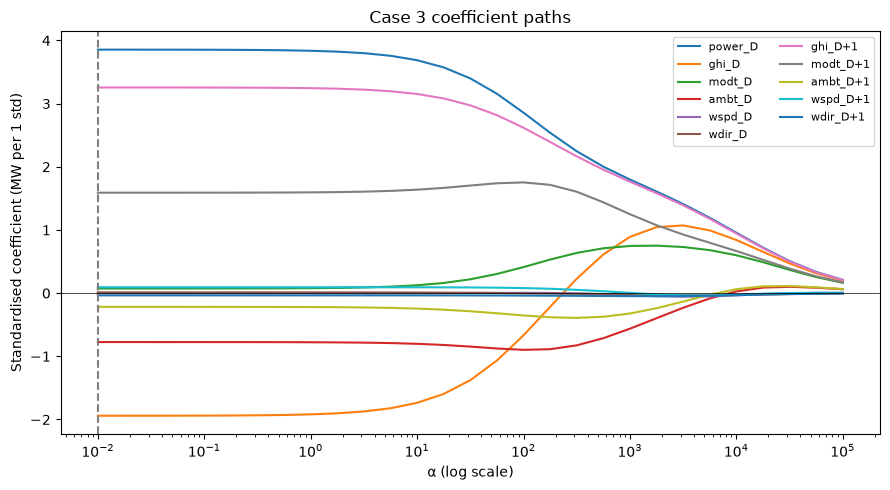

In [12]:
features = CASES["Case 3"]
path = pd.DataFrame(
    [ridge_model(a).fit(train[features], train["power"])[-1].coef_ for a in ALPHAS],
    index=ALPHAS, columns=features,
)

fig, ax = plt.subplots(figsize=(9, 5))
for col in features:
    ax.plot(path.index, path[col], label=col)
ax.axvline(best_alpha.loc["Case 3", "alpha"], color="grey", linestyle="--")
ax.axhline(0, color="black", linewidth=0.5)
ax.set_xscale("log")
ax.set_xlabel("α (log scale)")
ax.set_ylabel("Standardised coefficient (MW per 1 std)")
ax.set_title("Case 3 coefficient paths")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## 9. Where does it fail? Worst validation days (Case 2, the realistic case)

In [13]:
daily_mae = (
    daytime[daytime["split"] == "val"]
    .assign(abs_err=lambda x: (x["Case 2"] - x["power"]).abs())
    .groupby("Date")["abs_err"]
    .mean()
    .round(2)
)
daily_mae.sort_values(ascending=False).head(5)

Date
2026-01-26    3.77
2026-01-27    3.58
2026-01-30    2.24
2026-01-23    2.04
2026-01-21    1.70
Name: abs_err, dtype: float64

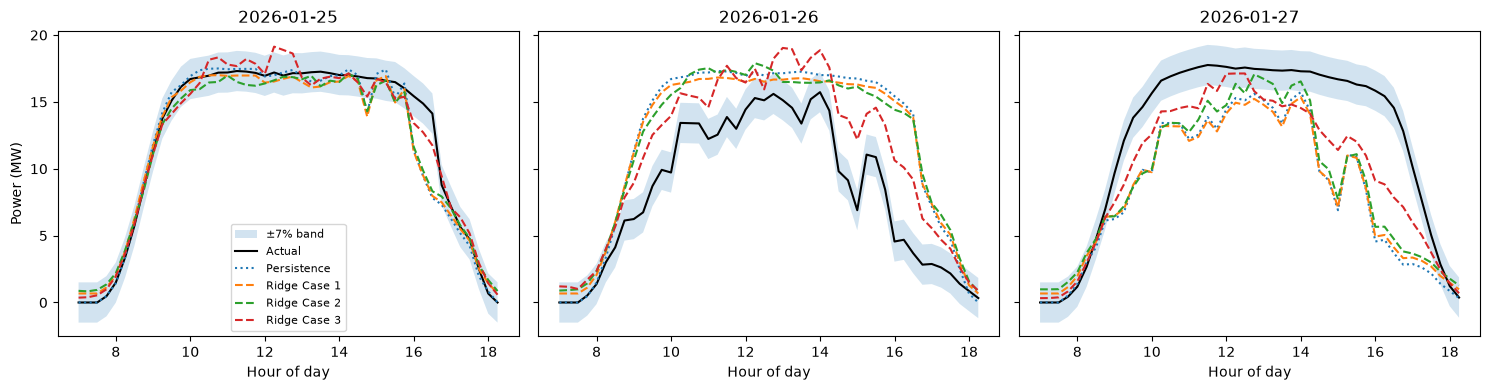

In [14]:
# Same three validation days as the other notebooks: clear, cloudy, clear.
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, day in zip(axes, ["2026-01-25", "2026-01-26", "2026-01-27"]):
    d = daytime[daytime["Date"] == day]
    hours = (d["Block"] - 1) / 4
    ax.fill_between(hours, d["power"] - BAND_MW, d["power"] + BAND_MW, alpha=0.2, label="±7% band")
    ax.plot(hours, d["power"], color="black", label="Actual")
    ax.plot(hours, d["power_D"], ":", label="Persistence")
    for case in CASES:
        ax.plot(hours, d[case], "--", label=f"Ridge {case}")
    ax.set_title(day)
    ax.set_xlabel("Hour of day")
axes[0].set_ylabel("Power (MW)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 10. Save forecasts, scores and the α search

In [15]:
(RESULTS / "predictions").mkdir(parents=True, exist_ok=True)
(RESULTS / "metrics").mkdir(parents=True, exist_ok=True)

# Every block, with night forecasts set to 0.
out = df[["TimeStamp", "Date", "Block", "split", "power"]].rename(columns={"power": "actual"})
for case in CASES:
    out[f"Ridge {case}"] = daytime[case].reindex(out.index).fillna(0.0)

out.to_csv(RESULTS / "predictions" / "ridge.csv", index=False)
metrics.to_csv(RESULTS / "metrics" / "ridge.csv", index=False)
coefs.to_csv(RESULTS / "metrics" / "ridge_coefficients.csv")
search.to_csv(RESULTS / "metrics" / "ridge_alpha_search.csv", index=False)